# Lab 05 - Learning Vector Quantization (LVQ)

**Name:** Zain Ul Wahaj
**Roll Number:** FA23-BAI-058
**Course:** Artificial Neural Networks

---

Complete solution to all **9 tasks** of Lab 05. Each part is solved in its own
code cell, directly below the question it answers, with its output shown underneath.

### Contents

1. **Task 1** - The LVQ Algorithm from the Lab Manual
2. **Task 2** - Dataset Loading and Preprocessing
3. **Task 3** - Distance and the Winning Prototype
4. **Task 4** - Prototype Initialization
5. **Task 5** - The LVQ1 Update Rule
6. **Task 6** - Training Loop
7. **Task 7** - Classification and Evaluation
8. **Task 8** - Hyperparameter Experiments
9. **Task 9** - Mini Project with Your Own Data

In [1]:
# Zain Ul Wahaj | FA23-BAI-058
# Artificial Neural Networks - Lab 05 - Learning Vector Quantization (LVQ)

import math

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

SEED = 58                      # roll number, so every run reproduces exactly
rng = np.random.default_rng(SEED)

print("numpy     ", np.__version__)
print("matplotlib", matplotlib.__version__)

numpy      2.5.4
matplotlib 3.11.2


---

## Task 1: The LVQ Algorithm from the Lab Manual

**Topic:** The manual's solved activity, the three bugs in its listing, and what LVQ actually does

### Task 1 (a)

> Write the LVQ class from the lab manual: a winner() method that returns the index of the prototype closest to a sample by Euclidean distance.

In [2]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 1 (a)
class LVQ:
    """LVQ as printed in the lab manual, with its bugs corrected.

    The manual hard-codes exactly two prototypes, so this class does too.
    Task 3 onwards replaces it with a version that handles any number.
    """

    def winner(self, weights, sample):
        # Squared Euclidean distance from the sample to each of the two prototypes.
        # Squaring is enough: whichever is smaller is also smaller after a square root,
        # so there is no need to pay for math.sqrt here.
        D0 = 0
        D1 = 0
        for i in range(len(sample)):
            D0 = D0 + math.pow(sample[i] - weights[0][i], 2)
            D1 = D1 + math.pow(sample[i] - weights[1][i], 2)

        # BUG 1 in the manual: it writes `if D0 > D1: return 0`, which returns the
        # prototype that is FARTHER away. The winner is the nearest one.
        return 0 if D0 < D1 else 1


print("winner() defined - returns 0 or 1, whichever prototype is nearer")

winner() defined - returns 0 or 1, whichever prototype is nearer


### Task 1 (b)

> Write the update() method that moves the winning prototype towards the sample when the prediction is right and away from it when the prediction is wrong.

In [3]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 1 (b)
def _update(self, weights, sample, J, alpha, actual):
    """Move prototype J towards the sample (reward) or away from it (punish)."""
    # BUG 2 in the manual: `if actual -- j:` is not a comparison at all. `--` is two
    # unary minus signs, and `j` is lower case while the argument is `J`. It should
    # be `if actual == J:` - the winning prototype's own index IS its class label,
    # because prototype 0 was initialised from a class-0 sample and prototype 1 from
    # a class-1 sample.
    if actual == J:
        # Correct class: pull the prototype towards the sample.
        # BUG 3 in the manual: it loops over `range(len(weights))`, which is the number
        # of PROTOTYPES (2), not the number of FEATURES (4). Only the first two features
        # of the winner would ever get updated.
        for i in range(len(weights[J])):
            weights[J][i] = weights[J][i] + alpha * (sample[i] - weights[J][i])
    else:
        # Wrong class: push the prototype away from the sample.
        for i in range(len(weights[J])):
            weights[J][i] = weights[J][i] - alpha * (sample[i] - weights[J][i])


LVQ.update = _update
print("update() attached to LVQ - reward moves +alpha, punish moves -alpha")

update() attached to LVQ - reward moves +alpha, punish moves -alpha


### Task 1 (c)

> Run the manual's driver code: six training samples, prototypes initialised from the first sample of each class, 3 epochs at alpha = 0.1, then classify T = [0, 0, 1, 0].

In [4]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 1 (c)
# Training samples (m, n) with their class vector, exactly as in the manual
X_toy = [[0, 0, 1, 1],
         [1, 0, 0, 0],
         [0, 0, 0, 1],
         [0, 1, 1, 0],
         [1, 1, 0, 0],
         [1, 1, 1, 0]]
Y_toy = [0, 1, 0, 1, 1, 1]

m, n = len(X_toy), len(X_toy[0])
print(f"m = {m} samples, n = {n} features, c = {len(set(Y_toy))} classes")

# Weight initialisation (n, c): take the first sample of each class as that class's
# prototype, then remove those samples so they are not also used for training.
weights = [X_toy.pop(0), X_toy.pop(0)]
Y_toy.pop(0)
Y_toy.pop(0)
m = m - 2

print("initial prototypes:", weights)
print(f"remaining training samples: {m}")

# Training
ob = LVQ()
epochs, alpha = 3, 0.1

for epoch in range(epochs):
    for j in range(m):
        T = X_toy[j]                       # sample selection
        J = ob.winner(weights, T)          # compute winner
        ob.update(weights, T, J, alpha, Y_toy[j])   # update weights
    print(f"after epoch {epoch + 1}: "
          f"[{', '.join(f'{w:.4f}' for w in weights[0])}] | "
          f"[{', '.join(f'{w:.4f}' for w in weights[1])}]")

# Classify a new input sample
T = [0, 0, 1, 0]
J = ob.winner(weights, T)
print()
print("Sample T belongs to class :", J)

m = 6 samples, n = 4 features, c = 2 classes
initial prototypes: [[0, 0, 1, 1], [1, 0, 0, 0]]
remaining training samples: 4
after epoch 1: [0.0000, -0.1000, 0.8900, 1.1000] | [1.0000, 0.1900, 0.1000, 0.0000]
after epoch 2: [0.0000, -0.1990, 0.7811, 1.1990] | [1.0000, 0.3439, 0.1810, 0.0000]
after epoch 3: [0.0000, -0.1791, 0.7030, 1.1791] | [0.9190, 0.5217, 0.3129, 0.0000]

Sample T belongs to class : 0


### Task 1 (d)

> Print the trained weights and list the bugs that had to be fixed before the manual's listing would run.

In [5]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 1 (d)
print("Trained weights:")
for k, w in enumerate(weights):
    print(f"   prototype {k} (class {k}): [{', '.join(f'{v:.4f}' for v in w)}]")

print()
print("Bugs in the manual's listing:")
print("  1. winner() returns 0 when D0 > D1, i.e. the FARTHER prototype wins.")
print("     Fixed by comparing D0 < D1.")
print("  2. update() tests `if actual -- j:`. `--` is not an equality operator and `j`")
print("     is not defined in that scope. Fixed to `if actual == J:`.")
print("  3. update() loops over range(len(weights)) = 2 prototypes instead of")
print("     range(len(weights[J])) = 4 features, so two of the four weights never move.")
print("     Fixed to loop over the features of the winning prototype.")
print("  (The listing is also indented inconsistently, so it raises IndentationError")
print("   before any of the three logic bugs can be reached.)")

Trained weights:
   prototype 0 (class 0): [0.0000, -0.1791, 0.7030, 1.1791]
   prototype 1 (class 1): [0.9190, 0.5217, 0.3129, 0.0000]

Bugs in the manual's listing:
  1. winner() returns 0 when D0 > D1, i.e. the FARTHER prototype wins.
     Fixed by comparing D0 < D1.
  2. update() tests `if actual -- j:`. `--` is not an equality operator and `j`
     is not defined in that scope. Fixed to `if actual == J:`.
  3. update() loops over range(len(weights)) = 2 prototypes instead of
     range(len(weights[J])) = 4 features, so two of the four weights never move.
     Fixed to loop over the features of the winning prototype.
  (The listing is also indented inconsistently, so it raises IndentationError
   before any of the three logic bugs can be reached.)


---

## Task 2: Dataset Loading and Preprocessing

**Topic:** Wine from the UCI ML Repository, class balance, a stratified split and feature scaling

### Task 2 (a)

> Download a dataset from the UCI machine learning repository, load it, and print its shape, feature names and class distribution.

In [6]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 2 (a)
from sklearn.datasets import load_wine

# Wine (UCI ML Repository, dataset 109). It ships inside scikit-learn, so the notebook
# runs offline and reproduces exactly - no download step that can rot.
# 178 samples, 13 chemical measurements, 3 cultivars. Multiclass on purpose: LVQ is
# a prototype method and handles more than two classes without any change.
wine = load_wine()
X_raw, y = wine.data, wine.target

print("data shape  :", X_raw.shape)
print("target shape:", y.shape)
print("classes     :", list(wine.target_names))
print()
print("features:")
for i, name in enumerate(wine.feature_names):
    print(f"  {i:>2}. {name}")

print()
counts = np.bincount(y)
for c, name in enumerate(wine.target_names):
    print(f"class {c} ({name}): {counts[c]:>3} samples  {counts[c] / len(y):>6.1%}")

data shape  : (178, 13)
target shape: (178,)
classes     : [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]

features:
   0. alcohol
   1. malic_acid
   2. ash
   3. alcalinity_of_ash
   4. magnesium
   5. total_phenols
   6. flavanoids
   7. nonflavanoid_phenols
   8. proanthocyanins
   9. color_intensity
  10. hue
  11. od280/od315_of_diluted_wines
  12. proline

class 0 (class_0):  59 samples   33.1%
class 1 (class_1):  71 samples   39.9%
class 2 (class_2):  48 samples   27.0%


### Task 2 (b)

> Split the data into training and test sets with a stratified split, and confirm the class proportions survived the split.

In [7]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 2 (b)
from sklearn.model_selection import train_test_split

# stratify=y keeps each cultivar's share the same in both halves. Without it a random
# 30% test split can easily take most of class 2, which has only 48 samples.
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X_raw, y, test_size=0.3, random_state=SEED, stratify=y
)

print(f"train: {X_tr_raw.shape[0]} samples   test: {X_te_raw.shape[0]} samples")
print()
print(f"{'class':<10}{'train':>10}{'test':>10}")
for c, name in enumerate(wine.target_names):
    print(f"{name:<10}{(y_tr == c).mean():>9.1%}{(y_te == c).mean():>10.1%}")

train: 124 samples   test: 54 samples

class          train      test
class_0       33.1%     33.3%
class_1       40.3%     38.9%
class_2       26.6%     27.8%


### Task 2 (c)

> Standardize the features. Explain why a distance-based model such as LVQ needs this, and why the scaler is fitted on the training set only.

In [8]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 2 (c)
from sklearn.preprocessing import StandardScaler

# LVQ picks a winner by Euclidean distance, and Euclidean distance adds up the squared
# difference of every feature. Wine's `proline` runs into the hundreds while
# `nonflavanoid_phenols` sits near 0.3, so without scaling proline alone decides which
# prototype wins and the other twelve measurements may as well not exist.
scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr_raw)   # fit on train only
X_te = scaler.transform(X_te_raw)       # test set is transformed with the train statistics

# Fitting on the full dataset would leak the test set's mean and variance into training,
# so the reported test accuracy would be optimistic.
print(f"{'feature':<32}{'raw range':>22}{'scaled range':>20}")
for i in [0, 4, 12]:
    name = wine.feature_names[i]
    print(f"{name:<32}"
          f"{f'{X_tr_raw[:, i].min():.2f} .. {X_tr_raw[:, i].max():.2f}':>22}"
          f"{f'{X_tr[:, i].min():.2f} .. {X_tr[:, i].max():.2f}':>20}")

print()
print(f"train mean after scaling: {X_tr.mean():.2e} (should be ~0)")
print(f"train std  after scaling: {X_tr.std():.4f} (should be ~1)")
print(f"test  mean after scaling: {X_te.mean():+.4f} (near 0, not exactly 0 - correct)")

feature                                      raw range        scaled range
alcohol                                 11.03 .. 14.83       -2.49 .. 2.16
magnesium                              70.00 .. 139.00       -2.18 .. 3.07
proline                              290.00 .. 1680.00       -1.42 .. 2.91

train mean after scaling: 2.98e-16 (should be ~0)
train std  after scaling: 1.0000 (should be ~1)
test  mean after scaling: -0.0442 (near 0, not exactly 0 - correct)


### Task 2 (d)

> Plot the spread of a few features before and after scaling to show the effect.

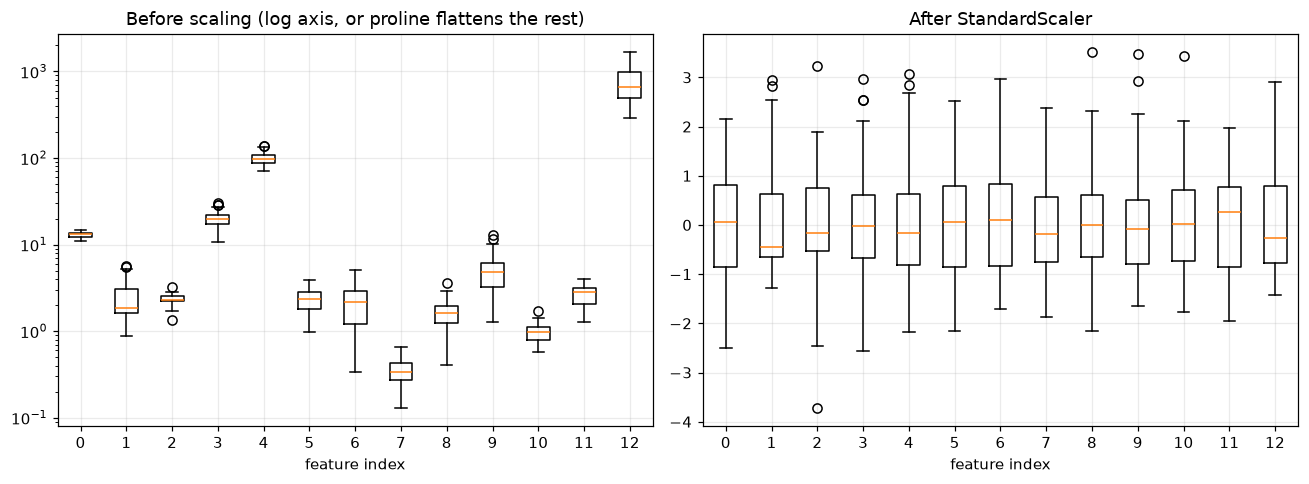

Largest / smallest feature std before scaling: 2,576x
Largest / smallest feature std after  scaling: 1.00x


In [9]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 2 (d)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].boxplot([X_tr_raw[:, i] for i in range(13)], tick_labels=range(13))
axes[0].set_yscale("log")
axes[0].set_title("Before scaling (log axis, or proline flattens the rest)")
axes[0].set_xlabel("feature index")

axes[1].boxplot([X_tr[:, i] for i in range(13)], tick_labels=range(13))
axes[1].set_title("After StandardScaler")
axes[1].set_xlabel("feature index")

plt.tight_layout()
plt.show()

ratio = X_tr_raw.std(axis=0).max() / X_tr_raw.std(axis=0).min()
print(f"Largest / smallest feature std before scaling: {ratio:,.0f}x")
print(f"Largest / smallest feature std after  scaling: {X_tr.std(axis=0).max() / X_tr.std(axis=0).min():.2f}x")

---

## Task 3: Distance and the Winning Prototype

**Topic:** A vectorized distance function and the competitive step that picks one winner

### Task 3 (a)

> Write a function euclidean_distance(a, b) that works both on two single vectors and on a whole set of prototypes against one sample.

In [10]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 3 (a)
def euclidean_distance(a, b):
    """Euclidean distance between a and b, computed along the last axis.

    Broadcasting does the work, so the same function covers both cases:
      - two vectors of shape (n,)           -> a single number
      - prototypes (p, n) against one (n,)  -> one distance per prototype, shape (p,)
    """
    return np.sqrt(np.sum((np.asarray(a) - np.asarray(b)) ** 2, axis=-1))


v1 = np.array([0.0, 3.0, 4.0])
v2 = np.array([0.0, 0.0, 0.0])
print("distance between two vectors:", euclidean_distance(v1, v2), "(expected 5.0)")

protos_demo = np.array([[0.0, 0.0, 0.0], [1.0, 1.0, 1.0], [0.0, 3.0, 4.0]])
print("one sample against 3 prototypes:", np.round(euclidean_distance(protos_demo, v1), 4))

distance between two vectors: 5.0 (expected 5.0)
one sample against 3 prototypes: [5.     3.7417 0.    ]


### Task 3 (b)

> Write find_winner(prototypes, sample) that returns the index of the closest prototype - the competitive step of LVQ.

In [11]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 3 (b)
def find_winner(prototypes, sample):
    """Index of the prototype nearest to `sample`.

    This is the whole competitive layer: every prototype computes its distance,
    the smallest one wins, and only that one is allowed to learn.
    """
    return int(np.argmin(euclidean_distance(prototypes, sample)))


# Three throwaway prototypes to check the function picks the obvious winner
test_protos = np.array([[0.0, 0.0], [5.0, 5.0], [10.0, 0.0]])
for s in ([0.2, 0.1], [4.0, 6.0], [9.0, 1.0]):
    j = find_winner(test_protos, np.array(s))
    print(f"sample {str(s):<12} -> prototype {j} at {test_protos[j]}")

sample [0.2, 0.1]   -> prototype 0 at [0. 0.]
sample [4.0, 6.0]   -> prototype 1 at [5. 5.]
sample [9.0, 1.0]   -> prototype 2 at [10.  0.]


### Task 3 (c)

> Check the vectorized version against a plain Python loop over the prototypes.

In [12]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 3 (c)
def find_winner_loop(prototypes, sample):
    """Same thing written the slow way, as a correctness check."""
    best_j, best_d = 0, float("inf")
    for j in range(len(prototypes)):
        d = 0.0
        for i in range(len(sample)):
            d += (sample[i] - prototypes[j][i]) ** 2
        d = math.sqrt(d)
        if d < best_d:
            best_j, best_d = j, d
    return best_j


# 40 random prototypes in 13-D, checked against 40 random training samples
check_protos = rng.normal(size=(40, 13))
agree = sum(
    find_winner(check_protos, X_tr[i]) == find_winner_loop(check_protos, X_tr[i])
    for i in range(40)
)
print(f"vectorized and loop versions agree on {agree}/40 samples")

vectorized and loop versions agree on 40/40 samples


### Task 3 (d)

> Plot the distance from one test sample to every prototype and mark the winner.

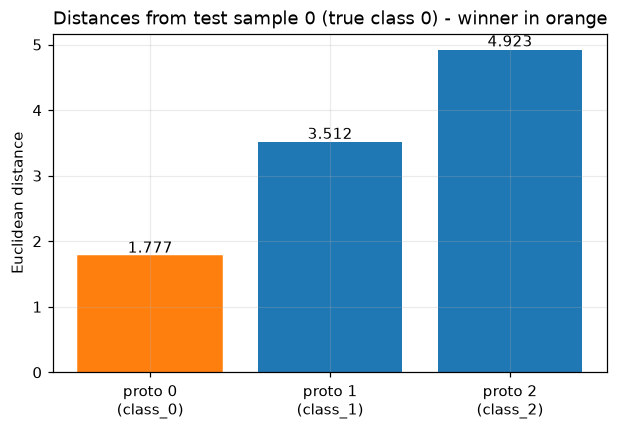

winner = prototype 0, true class = 0 -> correct


In [13]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 3 (d)
# One prototype per class, taken as that class's mean, so the picture is easy to read
mean_protos = np.array([X_tr[y_tr == c].mean(axis=0) for c in range(3)])
sample = X_te[0]

dists = euclidean_distance(mean_protos, sample)
winner = find_winner(mean_protos, sample)

plt.figure(figsize=(6.5, 4))
bars = plt.bar(range(3), dists, color=["tab:blue"] * 3)
bars[winner].set_color("tab:orange")
plt.xticks(range(3), [f"proto {c}\n({wine.target_names[c]})" for c in range(3)])
plt.ylabel("Euclidean distance")
plt.title(f"Distances from test sample 0 (true class {y_te[0]}) - winner in orange")
for c, d in enumerate(dists):
    plt.text(c, d + 0.05, f"{d:.3f}", ha="center")
plt.show()

print(f"winner = prototype {winner}, true class = {y_te[0]} -> "
      f"{'correct' if winner == y_te[0] else 'wrong'}")

---

## Task 4: Prototype Initialization

**Topic:** Three ways to place the starting prototypes and what each one costs

### Task 4 (a)

> Implement the manual's initialisation: take the first sample of each class as that class's prototype and remove those samples from training.

In [14]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 4 (a)
def init_from_first_samples(X, y):
    """The lab manual's scheme: first sample of each class becomes its prototype.

    Returns the prototypes, their labels, and a mask of the samples still free to
    train on - the manual is explicit that an initialising sample must be discarded.
    """
    classes = np.unique(y)
    protos, labels, used = [], [], []
    for c in classes:
        idx = int(np.flatnonzero(y == c)[0])
        protos.append(X[idx].copy())
        labels.append(c)
        used.append(idx)
    free = np.ones(len(X), dtype=bool)
    free[used] = False
    return np.array(protos), np.array(labels), free


p_first, l_first, free_mask = init_from_first_samples(X_tr, y_tr)
print("prototypes shape:", p_first.shape, " labels:", l_first)
print(f"training samples left: {free_mask.sum()} of {len(X_tr)}")
print()
print("A single sample is a noisy prototype - it carries that sample's own measurement")
print("error straight into the starting position.")

prototypes shape: (3, 13)  labels: [0 1 2]
training samples left: 121 of 124

A single sample is a noisy prototype - it carries that sample's own measurement
error straight into the starting position.


### Task 4 (b)

> Implement initialisation from the class means, and compare the starting positions with the previous method.

In [15]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 4 (b)
def init_from_class_means(X, y):
    """Each class's mean vector becomes its prototype. No samples are consumed."""
    classes = np.unique(y)
    protos = np.array([X[y == c].mean(axis=0) for c in classes])
    return protos, classes


p_mean, l_mean = init_from_class_means(X_tr, y_tr)

print(f"{'class':<8}{'dist(first, mean)':>20}{'||first||':>12}{'||mean||':>12}")
for c in range(3):
    d = euclidean_distance(p_first[c], p_mean[c])
    print(f"{c:<8}{d:>20.4f}{np.linalg.norm(p_first[c]):>12.4f}"
          f"{np.linalg.norm(p_mean[c]):>12.4f}")

print()
print("The mean sits much closer to the centre of its class, so training starts from a")
print("better place and needs fewer corrections.")

class      dist(first, mean)   ||first||    ||mean||
0                     2.1024      3.5075      2.4688
1                     4.2653      4.2365      1.7032
2                     2.3761      3.3931      3.0510

The mean sits much closer to the centre of its class, so training starts from a
better place and needs fewer corrections.


### Task 4 (c)

> Implement initialisation with more than one prototype per class, drawn at random from each class's own samples.

In [16]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 4 (c)
def init_prototypes(X, y, per_class=1, seed=SEED):
    """`per_class` prototypes for every class, sampled from that class's own points.

    More prototypes let one class occupy several separate regions of the space,
    which a single prototype per class cannot represent.
    """
    local_rng = np.random.default_rng(seed)
    classes = np.unique(y)
    protos, labels = [], []
    for c in classes:
        members = np.flatnonzero(y == c)
        picks = local_rng.choice(members, size=per_class, replace=False)
        for p in picks:
            protos.append(X[p].copy())
            labels.append(c)
    return np.array(protos), np.array(labels)


for k in (1, 2, 4):
    p, l = init_prototypes(X_tr, y_tr, per_class=k)
    print(f"per_class={k} -> prototypes {p.shape}, labels {l}")

per_class=1 -> prototypes (3, 13), labels [0 1 2]
per_class=2 -> prototypes (6, 13), labels [0 0 1 1 2 2]
per_class=4 -> prototypes (12, 13), labels [0 0 0 0 1 1 1 1 2 2 2 2]


### Task 4 (d)

> Project the training data to two dimensions with PCA and plot where each initialisation puts its prototypes.

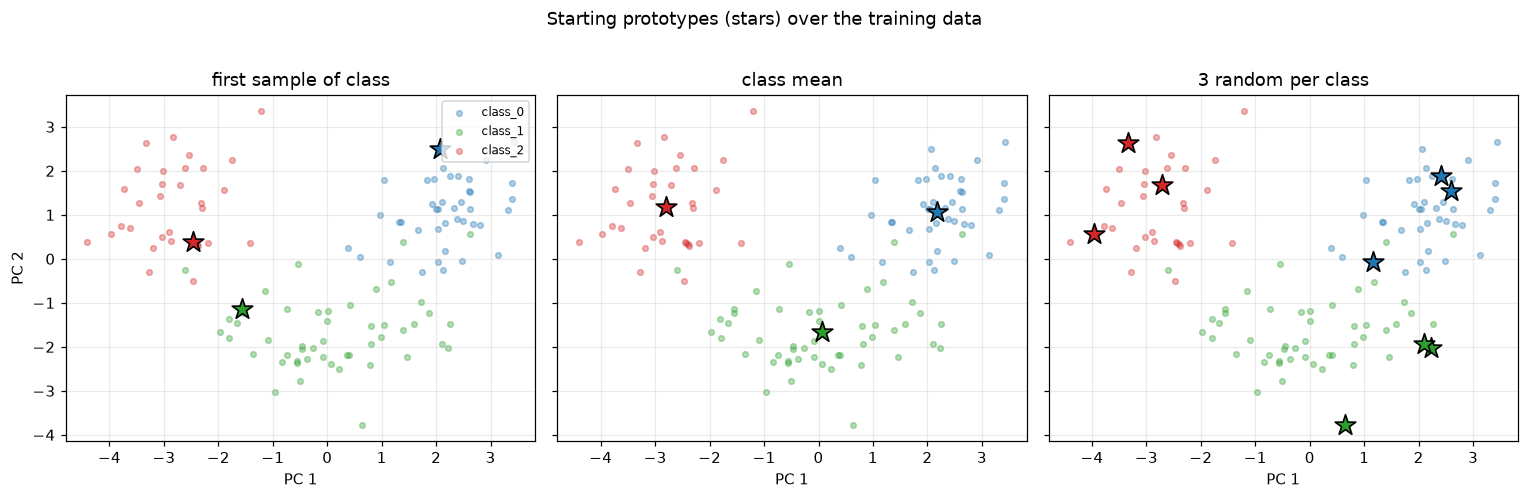

PCA keeps 54.6% of the variance in 2 components,
so the picture is indicative rather than the space LVQ actually works in.


In [17]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 4 (d)
from sklearn.decomposition import PCA

# PCA is used for drawing only - LVQ itself still trains on all 13 features
pca = PCA(n_components=2, random_state=SEED)
X_tr_2d = pca.fit_transform(X_tr)
p_rand, l_rand = init_prototypes(X_tr, y_tr, per_class=3)

sets = [("first sample of class", p_first, l_first),
        ("class mean", p_mean, l_mean),
        ("3 random per class", p_rand, l_rand)]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True)
colours = ["tab:blue", "tab:green", "tab:red"]

for ax, (title, protos, labels) in zip(axes, sets):
    for c in range(3):
        pts = X_tr_2d[y_tr == c]
        ax.scatter(pts[:, 0], pts[:, 1], s=14, alpha=0.35, color=colours[c],
                   label=wine.target_names[c])
    pr = pca.transform(protos)
    for c in range(3):
        sel = labels == c
        ax.scatter(pr[sel, 0], pr[sel, 1], s=200, marker="*",
                   color=colours[c], edgecolor="black", linewidth=1.1, zorder=5)
    ax.set_title(title)
    ax.set_xlabel("PC 1")

axes[0].set_ylabel("PC 2")
axes[0].legend(fontsize=8, loc="upper right")
plt.suptitle("Starting prototypes (stars) over the training data", y=1.02)
plt.tight_layout()
plt.show()

print(f"PCA keeps {pca.explained_variance_ratio_.sum():.1%} of the variance in 2 components,")
print("so the picture is indicative rather than the space LVQ actually works in.")

---

## Task 5: The LVQ1 Update Rule

**Topic:** Reward and punish, one step at a time, and what the learning rate controls

### Task 5 (a)

> Write update_prototype(proto, sample, alpha, correct) implementing the LVQ1 rule.

In [18]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 5 (a)
def update_prototype(proto, sample, alpha, correct):
    """One LVQ1 step.

        w_j <- w_j + alpha * (x - w_j)   if the winner's label matches the sample
        w_j <- w_j - alpha * (x - w_j)   otherwise

    Only the winner moves. Everything else is left alone, which is what makes this
    competitive learning rather than gradient descent over all the weights.
    """
    sign = 1.0 if correct else -1.0
    return proto + sign * alpha * (sample - proto)


w = np.array([0.0, 0.0])
x = np.array([1.0, 2.0])
print("prototype      ", w)
print("sample         ", x)
print("reward (a=0.5) ", update_prototype(w, x, 0.5, True), " moves halfway towards x")
print("punish (a=0.5) ", update_prototype(w, x, 0.5, False), " moves the same distance away")

prototype       [0. 0.]
sample          [1. 2.]
reward (a=0.5)  [0.5 1. ]  moves halfway towards x
punish (a=0.5)  [-0.5 -1. ]  moves the same distance away


### Task 5 (b)

> Take one real training sample, find its winner, apply one update and print the prototype before and after.

In [19]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 5 (b)
protos_demo = p_mean.copy()
labels_demo = l_mean.copy()

i = 0
sample, true_c = X_tr[i], y_tr[i]
j = find_winner(protos_demo, sample)
correct = labels_demo[j] == true_c

before = protos_demo[j].copy()
protos_demo[j] = update_prototype(protos_demo[j], sample, 0.3, correct)
after = protos_demo[j]

print(f"sample {i}: true class {true_c}, winner = prototype {j} (class {labels_demo[j]})")
print(f"-> {'REWARD, pull towards' if correct else 'PUNISH, push away from'} the sample")
print()
print(f"{'feature':<4}{'before':>10}{'after':>10}{'change':>10}")
for f in range(5):
    print(f"{f:<4}{before[f]:>10.4f}{after[f]:>10.4f}{after[f] - before[f]:>+10.4f}")
print("...")
print()
print(f"distance to sample before: {euclidean_distance(before, sample):.4f}")
print(f"distance to sample after : {euclidean_distance(after, sample):.4f}")

sample 0: true class 0, winner = prototype 0 (class 0)
-> REWARD, pull towards the sample

feature    before     after    change
0       0.9149    1.0929   +0.1780
1      -0.2427   -0.2825   -0.0398
2       0.2714    0.5892   +0.3178
3      -0.7814   -0.5100   +0.2714
4       0.5344    0.8610   +0.3265
...

distance to sample before: 2.1024
distance to sample after : 1.4717


### Task 5 (c)

> Show how the size of the step depends on alpha.

In [20]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 5 (c)
base = p_mean[1].copy()
sample = X_tr[np.flatnonzero(y_tr == 1)[3]]
d0 = euclidean_distance(base, sample)

print(f"starting distance to the sample: {d0:.4f}")
print()
print(f"{'alpha':>8}{'dist after reward':>20}{'dist after punish':>20}{'% closed':>12}")
for a in (0.01, 0.05, 0.1, 0.3, 0.5, 1.0):
    dr = euclidean_distance(update_prototype(base, sample, a, True), sample)
    dp = euclidean_distance(update_prototype(base, sample, a, False), sample)
    print(f"{a:>8}{dr:>20.4f}{dp:>20.4f}{1 - dr / d0:>11.0%}")

print()
print("alpha is the fraction of the remaining gap closed in one step, so alpha = 1 lands")
print("the prototype exactly on the sample and throws away everything it had learned.")

starting distance to the sample: 3.5489

   alpha   dist after reward   dist after punish    % closed
    0.01              3.5134              3.5844         1%
    0.05              3.3715              3.7263         5%
     0.1              3.1940              3.9038        10%
     0.3              2.4842              4.6136        30%
     0.5              1.7744              5.3233        50%
     1.0              0.0000              7.0978       100%

alpha is the fraction of the remaining gap closed in one step, so alpha = 1 lands
the prototype exactly on the sample and throws away everything it had learned.


### Task 5 (d)

> Plot the path a prototype takes over several updates towards one sample.

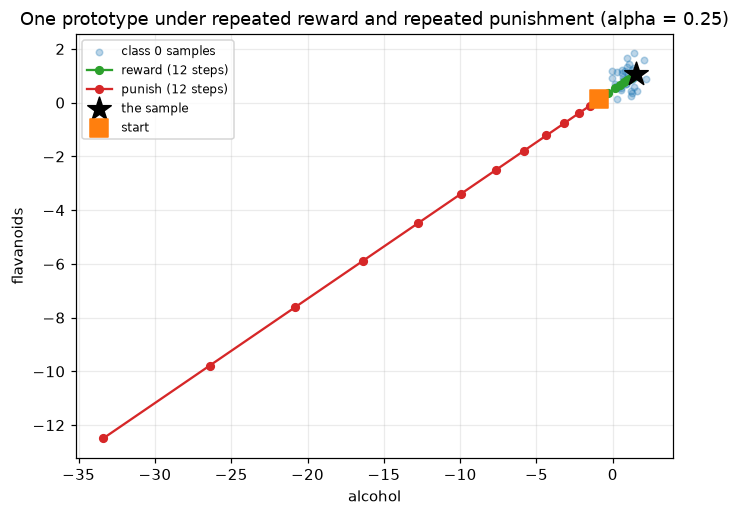

reward: distance went 2.572 -> 0.081
punish: distance went 2.572 -> 37.434
Reward converges on the sample geometrically. Punishment diverges, which is why
alpha has to decay - a large alpha late in training destroys a good prototype.


In [21]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 5 (d)
# Two features only, so the path can actually be drawn
f1, f2 = 0, 6
target = X_tr[np.flatnonzero(y_tr == 0)[0], [f1, f2]]
path = [p_mean[1, [f1, f2]].copy()]
for _ in range(12):
    path.append(update_prototype(path[-1], target, 0.25, True))
path = np.array(path)

away = [p_mean[1, [f1, f2]].copy()]
for _ in range(12):
    away.append(update_prototype(away[-1], target, 0.25, False))
away = np.array(away)

plt.figure(figsize=(7, 5))
plt.scatter(X_tr[y_tr == 0, f1], X_tr[y_tr == 0, f2], s=18, alpha=0.3,
            color="tab:blue", label="class 0 samples")
plt.plot(path[:, 0], path[:, 1], "o-", color="tab:green", ms=5, label="reward (12 steps)")
plt.plot(away[:, 0], away[:, 1], "o-", color="tab:red", ms=5, label="punish (12 steps)")
plt.scatter(*target, s=260, marker="*", color="black", zorder=5, label="the sample")
plt.scatter(*path[0], s=140, marker="s", color="tab:orange", zorder=5, label="start")
plt.xlabel(wine.feature_names[f1])
plt.ylabel(wine.feature_names[f2])
plt.title("One prototype under repeated reward and repeated punishment (alpha = 0.25)")
plt.legend(fontsize=8)
plt.show()

print(f"reward: distance went {euclidean_distance(path[0], target):.3f} -> "
      f"{euclidean_distance(path[-1], target):.3f}")
print(f"punish: distance went {euclidean_distance(away[0], target):.3f} -> "
      f"{euclidean_distance(away[-1], target):.3f}")
print("Reward converges on the sample geometrically. Punishment diverges, which is why")
print("alpha has to decay - a large alpha late in training destroys a good prototype.")

---

## Task 6: Training Loop

**Topic:** A full LVQ1 training algorithm with a decaying learning rate

### Task 6 (a)

> Write train_lvq() that runs the update rule over all samples for a number of epochs, with the learning rate decaying as training goes on.

In [22]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 6 (a)
def predict(X, protos, proto_labels):
    """Label every row of X with the class of its nearest prototype."""
    # (samples, 1, features) - (1, prototypes, features) -> (samples, prototypes)
    d = np.sqrt(((np.asarray(X)[:, None, :] - protos[None, :, :]) ** 2).sum(axis=-1))
    return proto_labels[np.argmin(d, axis=1)]


def train_lvq(X, y, per_class=1, epochs=30, alpha0=0.3, seed=SEED, track=None):
    """Train an LVQ1 classifier.

    Returns the prototypes, their labels, and a per-epoch history of
    (epoch, alpha, train accuracy, test accuracy).
    """
    local_rng = np.random.default_rng(seed)
    protos, labels = init_prototypes(X, y, per_class=per_class, seed=seed)
    history = []

    for epoch in range(epochs):
        # Linear decay: large steps early to move the prototypes into place, small
        # steps later so a single odd sample cannot undo the whole epoch.
        alpha = alpha0 * (1 - epoch / epochs)

        # Shuffle every epoch, otherwise the last class in the file always gets the
        # final say on where the prototypes end up.
        for i in local_rng.permutation(len(X)):
            j = find_winner(protos, X[i])
            protos[j] = update_prototype(protos[j], X[i], alpha, labels[j] == y[i])

        train_acc = (predict(X, protos, labels) == y).mean()
        test_acc = (predict(track[0], protos, labels) == track[1]).mean() if track else np.nan
        history.append((epoch + 1, alpha, train_acc, test_acc))

    return protos, labels, np.array(history)


print("train_lvq() defined")

train_lvq() defined


### Task 6 (b)

> Train the model on the Wine training set and print the accuracy at the start and the end of training.

In [23]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 6 (b)
protos, proto_labels, hist = train_lvq(
    X_tr, y_tr, per_class=1, epochs=40, alpha0=0.3, track=(X_te, y_te)
)

print(f"prototypes: {protos.shape[0]} ({protos.shape[0] // 3} per class), "
      f"{protos.shape[1]} features each")
print()
print(f"{'epoch':>7}{'alpha':>10}{'train acc':>12}{'test acc':>11}")
for row in hist[[0, 1, 4, 9, 19, 29, 39]]:
    print(f"{int(row[0]):>7}{row[1]:>10.4f}{row[2]:>12.2%}{row[3]:>11.2%}")

print()
print(f"final train accuracy: {hist[-1, 2]:.2%}")
print(f"final test  accuracy: {hist[-1, 3]:.2%}")

prototypes: 3 (1 per class), 13 features each

  epoch     alpha   train acc   test acc
      1    0.3000      93.55%     94.44%
      2    0.2925      95.97%     88.89%
      5    0.2700      93.55%     85.19%
     10    0.2325      96.77%     87.04%
     20    0.1575      96.77%     94.44%
     30    0.0825      98.39%     90.74%
     40    0.0075      98.39%     94.44%

final train accuracy: 98.39%
final test  accuracy: 94.44%


### Task 6 (c)

> Plot the learning curve together with the decaying learning rate.

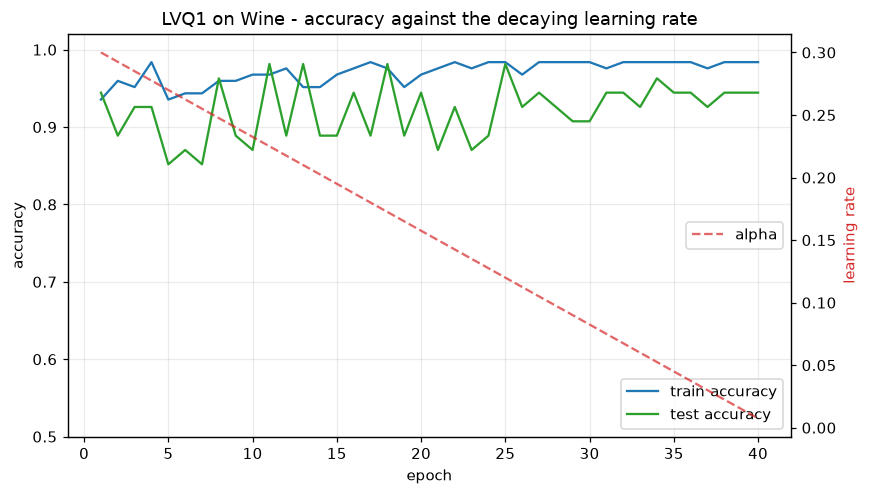

best test accuracy 98.15% first reached at epoch 11
accuracy swings by 11.11% over the last 20 epochs,
which shrinks as alpha decays - that is the decay doing its job.


In [24]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 6 (c)
fig, ax1 = plt.subplots(figsize=(8, 4.6))

ax1.plot(hist[:, 0], hist[:, 2], label="train accuracy", color="tab:blue")
ax1.plot(hist[:, 0], hist[:, 3], label="test accuracy", color="tab:green")
ax1.set_xlabel("epoch")
ax1.set_ylabel("accuracy")
ax1.set_ylim(0.5, 1.02)
ax1.legend(loc="lower right")

ax2 = ax1.twinx()
ax2.plot(hist[:, 0], hist[:, 1], "--", color="tab:red", alpha=0.7, label="alpha")
ax2.set_ylabel("learning rate", color="tab:red")
ax2.grid(False)
ax2.legend(loc="center right")

plt.title("LVQ1 on Wine - accuracy against the decaying learning rate")
plt.tight_layout()
plt.show()

best = hist[:, 3].argmax()
print(f"best test accuracy {hist[best, 3]:.2%} first reached at epoch {int(hist[best, 0])}")
print(f"accuracy swings by {hist[20:, 3].max() - hist[20:, 3].min():.2%} over the last 20 epochs,")
print("which shrinks as alpha decays - that is the decay doing its job.")

### Task 6 (d)

> Show where the prototypes ended up compared with where they started.

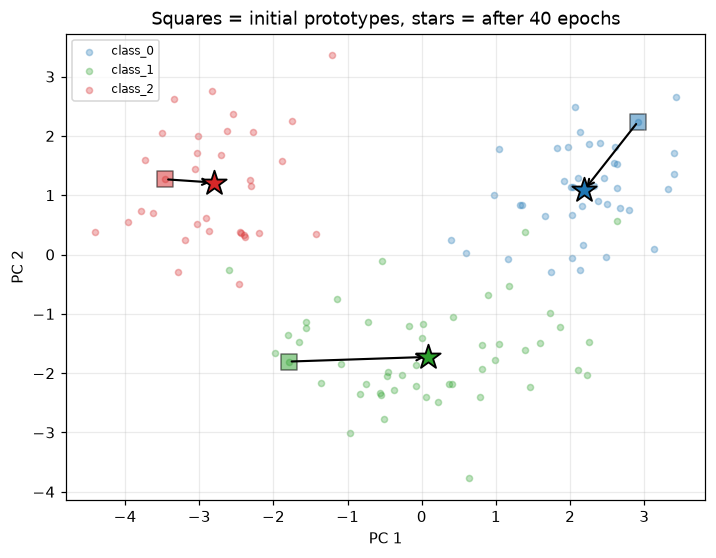

prototype 0 (class 0) moved 1.698 in the full 13-D space
prototype 1 (class 1) moved 3.079 in the full 13-D space
prototype 2 (class 2) moved 2.639 in the full 13-D space


In [25]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 6 (d)
start_protos, start_labels = init_prototypes(X_tr, y_tr, per_class=1, seed=SEED)
s2d, e2d = pca.transform(start_protos), pca.transform(protos)

plt.figure(figsize=(7.5, 5.5))
for c in range(3):
    pts = X_tr_2d[y_tr == c]
    plt.scatter(pts[:, 0], pts[:, 1], s=16, alpha=0.3, color=colours[c],
                label=wine.target_names[c])
for k in range(len(protos)):
    c = proto_labels[k]
    plt.annotate("", xy=e2d[k], xytext=s2d[k],
                 arrowprops=dict(arrowstyle="->", color="black", lw=1.4))
    plt.scatter(*s2d[k], s=120, marker="s", color=colours[c],
                edgecolor="black", alpha=0.5)
    plt.scatter(*e2d[k], s=280, marker="*", color=colours[c],
                edgecolor="black", linewidth=1.2, zorder=5)

plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("Squares = initial prototypes, stars = after 40 epochs")
plt.legend(fontsize=8)
plt.show()

moved = euclidean_distance(start_protos, protos)
for k in range(len(protos)):
    print(f"prototype {k} (class {proto_labels[k]}) moved {moved[k]:.3f} "
          f"in the full 13-D space")

---

## Task 7: Classification and Evaluation

**Topic:** Test accuracy, a confusion matrix, and how LVQ compares with 1-NN

### Task 7 (a)

> Classify the test set and report the overall accuracy and the per-class accuracy.

In [26]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 7 (a)
y_pred = predict(X_te, protos, proto_labels)
acc = (y_pred == y_te).mean()

print(f"test accuracy: {acc:.2%}  ({(y_pred == y_te).sum()}/{len(y_te)} correct)")
print()
print(f"{'class':<12}{'n':>5}{'correct':>10}{'accuracy':>11}")
for c in range(3):
    sel = y_te == c
    print(f"{wine.target_names[c]:<12}{sel.sum():>5}"
          f"{(y_pred[sel] == c).sum():>10}{(y_pred[sel] == c).mean():>11.1%}")

test accuracy: 94.44%  (51/54 correct)

class           n   correct   accuracy
class_0        18        18     100.0%
class_1        21        18      85.7%
class_2        15        15     100.0%


### Task 7 (b)

> Print a full classification report with precision, recall and F1 per class.

In [27]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 7 (b)
from sklearn.metrics import classification_report

print(classification_report(y_te, y_pred, target_names=wine.target_names, digits=3))

              precision    recall  f1-score   support

     class_0      0.947     1.000     0.973        18
     class_1      1.000     0.857     0.923        21
     class_2      0.882     1.000     0.938        15

    accuracy                          0.944        54
   macro avg      0.943     0.952     0.945        54
weighted avg      0.950     0.944     0.944        54



### Task 7 (c)

> Plot the confusion matrix and name the classes that get mixed up.

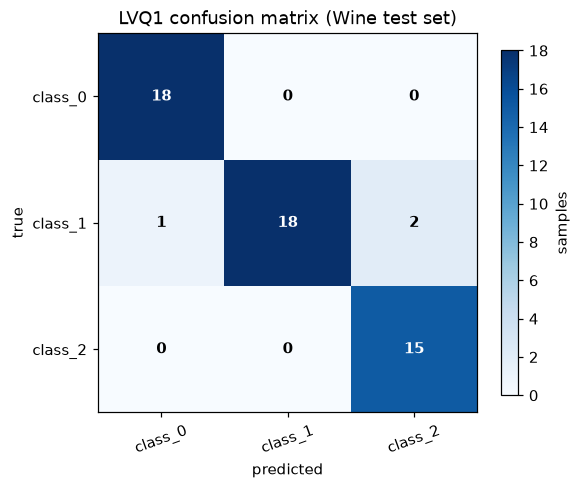

2 x class_1 predicted as class_2
1 x class_1 predicted as class_0


In [28]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 7 (c)
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_te, y_pred)

plt.figure(figsize=(5.4, 4.6))
plt.imshow(cm, cmap="Blues")
plt.colorbar(shrink=0.85, label="samples")
plt.xticks(range(3), wine.target_names, rotation=20)
plt.yticks(range(3), wine.target_names)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("LVQ1 confusion matrix (Wine test set)")
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontweight="bold")
plt.grid(False)
plt.tight_layout()
plt.show()

errors = [(i, j, cm[i, j]) for i in range(3) for j in range(3) if i != j and cm[i, j]]
if errors:
    for i, j, k in sorted(errors, key=lambda t: -t[2]):
        print(f"{k} x {wine.target_names[i]} predicted as {wine.target_names[j]}")
else:
    print("No off-diagonal entries - every test sample was classified correctly.")

### Task 7 (d)

> Compare LVQ with a 1-nearest-neighbour classifier and comment on how much the model compresses the training data.

In [29]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 7 (d)
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=1).fit(X_tr, y_tr)
knn_acc = knn.score(X_te, y_te)

print(f"{'model':<28}{'stored vectors':>16}{'test accuracy':>16}")
print(f"{'LVQ1 (1 proto/class)':<28}{len(protos):>16}{acc:>16.2%}")
print(f"{'1-NN':<28}{len(X_tr):>16}{knn_acc:>16.2%}")
print()
print(f"LVQ keeps {len(protos)} vectors instead of {len(X_tr)}, a "
      f"{len(X_tr) / len(protos):.0f}x reduction,")
print(f"for a difference in accuracy of {abs(acc - knn_acc):.2%}.")
print()
print("That trade is the point of LVQ. 1-NN has to carry the whole training set to")
print("classify anything, while LVQ answers with three vectors - and because each one")
print("is a point in the original feature space, it can be read as a description of")
print("what a typical member of that class looks like.")

model                         stored vectors   test accuracy
LVQ1 (1 proto/class)                       3          94.44%
1-NN                                     124          96.30%

LVQ keeps 3 vectors instead of 124, a 41x reduction,
for a difference in accuracy of 1.85%.

That trade is the point of LVQ. 1-NN has to carry the whole training set to
classify anything, while LVQ answers with three vectors - and because each one
is a point in the original feature space, it can be read as a description of
what a typical member of that class looks like.


---

## Task 8: Hyperparameter Experiments

**Topic:** Learning rate, epochs and prototypes per class, each varied on its own

### Task 8 (a)

> Vary the initial learning rate and record the test accuracy for each value.

In [30]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 8 (a)
alphas = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.8]
rows = []
for a in alphas:
    _, _, h = train_lvq(X_tr, y_tr, per_class=1, epochs=40, alpha0=a, track=(X_te, y_te))
    rows.append((a, h[-1, 2], h[-1, 3]))

print(f"{'alpha0':>8}{'train acc':>12}{'test acc':>11}")
for a, tr, te in rows:
    print(f"{a:>8}{tr:>12.2%}{te:>11.2%}")

best_alpha = max(rows, key=lambda r: r[2])[0]
print()
print(f"best test accuracy at alpha0 = {best_alpha}")

  alpha0   train acc   test acc
    0.01      98.39%     94.44%
    0.05      98.39%     94.44%
     0.1      98.39%     94.44%
     0.2      98.39%     94.44%
     0.3      98.39%     94.44%
     0.5      98.39%     94.44%
     0.8      40.32%     38.89%

best test accuracy at alpha0 = 0.01


### Task 8 (b)

> Vary the number of epochs and plot how accuracy responds.

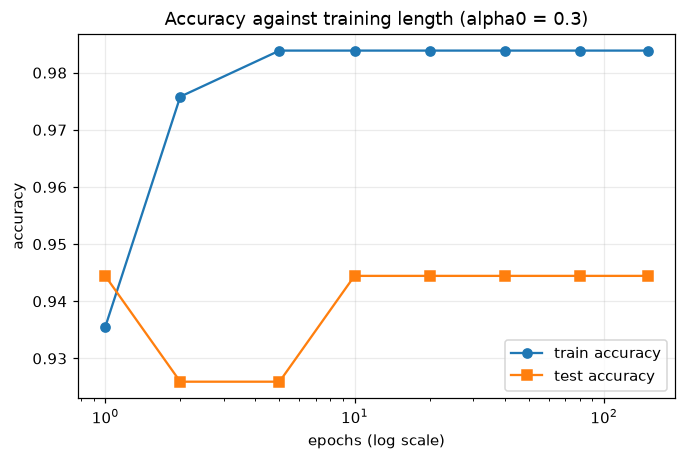

   1 epochs -> train 93.55%, test 94.44%
   2 epochs -> train 97.58%, test 92.59%
   5 epochs -> train 98.39%, test 92.59%
  10 epochs -> train 98.39%, test 94.44%
  20 epochs -> train 98.39%, test 94.44%
  40 epochs -> train 98.39%, test 94.44%
  80 epochs -> train 98.39%, test 94.44%
 150 epochs -> train 98.39%, test 94.44%


In [31]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 8 (b)
epoch_grid = [1, 2, 5, 10, 20, 40, 80, 150]
e_rows = []
for e in epoch_grid:
    _, _, h = train_lvq(X_tr, y_tr, per_class=1, epochs=e, alpha0=0.3, track=(X_te, y_te))
    e_rows.append((e, h[-1, 2], h[-1, 3]))

e_arr = np.array(e_rows)
plt.figure(figsize=(7, 4.3))
plt.plot(e_arr[:, 0], e_arr[:, 1], "o-", label="train accuracy")
plt.plot(e_arr[:, 0], e_arr[:, 2], "s-", label="test accuracy")
plt.xscale("log")
plt.xlabel("epochs (log scale)")
plt.ylabel("accuracy")
plt.title("Accuracy against training length (alpha0 = 0.3)")
plt.legend()
plt.show()

for e, tr, te in e_rows:
    print(f"{e:>4} epochs -> train {tr:.2%}, test {te:.2%}")

### Task 8 (c)

> Vary the number of prototypes per class and report what it costs and what it buys.

In [32]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 8 (c)
p_rows = []
for k in (1, 2, 3, 5, 8, 12):
    _, _, h = train_lvq(X_tr, y_tr, per_class=k, epochs=40, alpha0=0.3, track=(X_te, y_te))
    p_rows.append((k, 3 * k, h[-1, 2], h[-1, 3]))

print(f"{'per class':>10}{'total':>8}{'train acc':>12}{'test acc':>11}{'vs 1-NN store':>16}")
for k, tot, tr, te in p_rows:
    print(f"{k:>10}{tot:>8}{tr:>12.2%}{te:>11.2%}{f'{len(X_tr) / tot:.0f}x smaller':>16}")

print()
print("More prototypes let a class cover several regions, but each one is trained on")
print("fewer samples, so past a point they only memorise the training set.")

 per class   total   train acc   test acc   vs 1-NN store
         1       3      98.39%     94.44%     41x smaller
         2       6      99.19%     92.59%     21x smaller
         3       9      99.19%    100.00%     14x smaller
         5      15      99.19%     90.74%      8x smaller
         8      24      99.19%     92.59%      5x smaller
        12      36     100.00%     92.59%      3x smaller

More prototypes let a class cover several regions, but each one is trained on
fewer samples, so past a point they only memorise the training set.


### Task 8 (d)

> Run a grid over learning rate and prototypes per class and show the result as a heatmap.

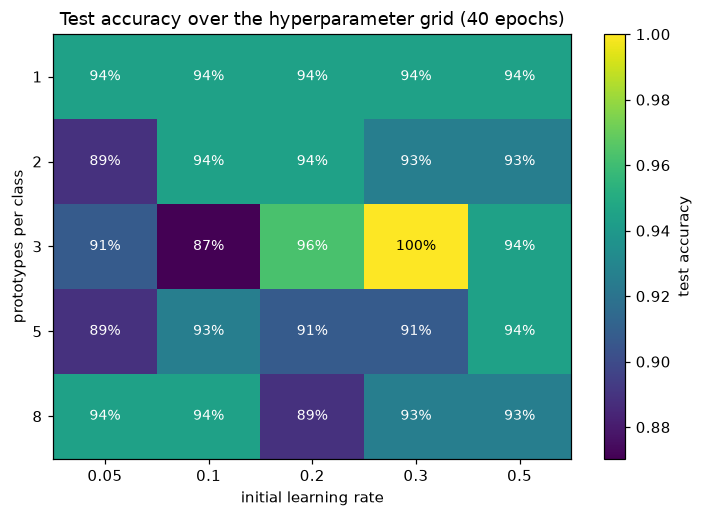

best cell: 3 prototypes/class at alpha0 = 0.3 -> 100.00%
spread across the whole grid: 87.04% to 100.00% (12.96% wide)


In [33]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 8 (d)
alpha_grid = [0.05, 0.1, 0.2, 0.3, 0.5]
proto_grid = [1, 2, 3, 5, 8]
grid = np.zeros((len(proto_grid), len(alpha_grid)))

for r, k in enumerate(proto_grid):
    for c, a in enumerate(alpha_grid):
        _, _, h = train_lvq(X_tr, y_tr, per_class=k, epochs=40, alpha0=a, track=(X_te, y_te))
        grid[r, c] = h[-1, 3]

plt.figure(figsize=(6.6, 4.8))
plt.imshow(grid, cmap="viridis", aspect="auto")
plt.colorbar(label="test accuracy")
plt.xticks(range(len(alpha_grid)), alpha_grid)
plt.yticks(range(len(proto_grid)), proto_grid)
plt.xlabel("initial learning rate")
plt.ylabel("prototypes per class")
plt.title("Test accuracy over the hyperparameter grid (40 epochs)")
for r in range(len(proto_grid)):
    for c in range(len(alpha_grid)):
        plt.text(c, r, f"{grid[r, c]:.0%}", ha="center", va="center",
                 color="white" if grid[r, c] < grid.max() * 0.97 else "black", fontsize=9)
plt.grid(False)
plt.tight_layout()
plt.show()

br, bc = np.unravel_index(grid.argmax(), grid.shape)
print(f"best cell: {proto_grid[br]} prototypes/class at alpha0 = {alpha_grid[bc]} "
      f"-> {grid[br, bc]:.2%}")
print(f"spread across the whole grid: {grid.min():.2%} to {grid.max():.2%} "
      f"({grid.max() - grid.min():.2%} wide)")

---

## Task 9: Mini Project with Your Own Data

**Topic:** LVQ on UCI Optical Recognition of Handwritten Digits, where the prototypes can be looked at

### Task 9 (a)

> Load a second dataset from the UCI repository, preprocess it, and describe it.

data shape: (1797, 64)  classes: 10
pixel range: 0.0 to 16.0
samples per class: [178 182 177 183 181 182 181 179 174 180]

train (1257, 64), test (540, 64), scaled to [0.00, 1.00]


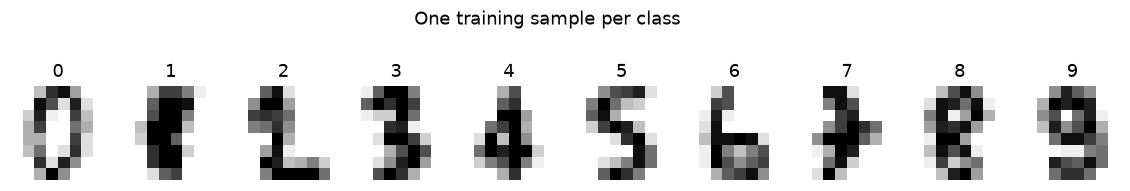

In [34]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 9 (a)
from sklearn.datasets import load_digits

# UCI Optical Recognition of Handwritten Digits (dataset 80): 8x8 greyscale images
# flattened to 64 features, 10 classes. Chosen because each prototype is itself a
# 64-value vector that can be folded back into an 8x8 image and looked at, which is
# the clearest way to see what a prototype actually learns.
digits = load_digits()
Xd_raw, yd = digits.data, digits.target

print("data shape:", Xd_raw.shape, " classes:", len(np.unique(yd)))
print("pixel range:", Xd_raw.min(), "to", Xd_raw.max())
print("samples per class:", np.bincount(yd))

Xd_tr_raw, Xd_te_raw, yd_tr, yd_te = train_test_split(
    Xd_raw, yd, test_size=0.3, random_state=SEED, stratify=yd
)

# Every feature is a pixel on the same 0-16 scale, so dividing by 16 is enough and
# keeps the vectors readable as images. StandardScaler would blow up the border
# pixels, which are 0 in almost every sample and so have near-zero variance.
Xd_tr, Xd_te = Xd_tr_raw / 16.0, Xd_te_raw / 16.0

print(f"\ntrain {Xd_tr.shape}, test {Xd_te.shape}, scaled to [{Xd_tr.min():.2f}, {Xd_tr.max():.2f}]")

fig, axes = plt.subplots(1, 10, figsize=(13, 1.7))
for c in range(10):
    axes[c].imshow(Xd_tr[yd_tr == c][0].reshape(8, 8), cmap="gray_r")
    axes[c].set_title(str(c))
    axes[c].axis("off")
plt.suptitle("One training sample per class", y=1.15)
plt.show()

### Task 9 (b)

> Train the LVQ model on this dataset and show the learning curve.

30 prototypes (3 per class) of 64 features
final train accuracy: 96.98%
final test  accuracy: 96.30%


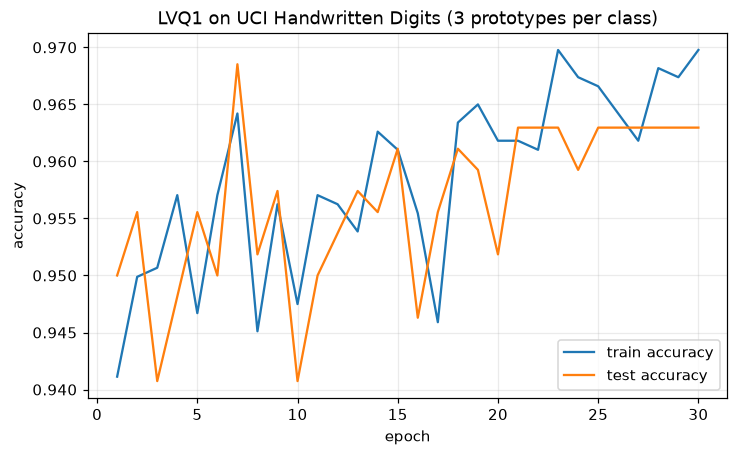

In [35]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 9 (b)
protos_d, labels_d, hist_d = train_lvq(
    Xd_tr, yd_tr, per_class=3, epochs=30, alpha0=0.2, track=(Xd_te, yd_te)
)

print(f"{protos_d.shape[0]} prototypes (3 per class) of {protos_d.shape[1]} features")
print(f"final train accuracy: {hist_d[-1, 2]:.2%}")
print(f"final test  accuracy: {hist_d[-1, 3]:.2%}")

plt.figure(figsize=(7.5, 4.3))
plt.plot(hist_d[:, 0], hist_d[:, 2], label="train accuracy")
plt.plot(hist_d[:, 0], hist_d[:, 3], label="test accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("LVQ1 on UCI Handwritten Digits (3 prototypes per class)")
plt.legend()
plt.show()

### Task 9 (c)

> Evaluate the model and display the learned prototypes as images.

LVQ test accuracy : 96.30%  (30 stored vectors)
1-NN test accuracy: 98.89%  (1257 stored vectors)
LVQ stores 42x less for 2.59% less accuracy


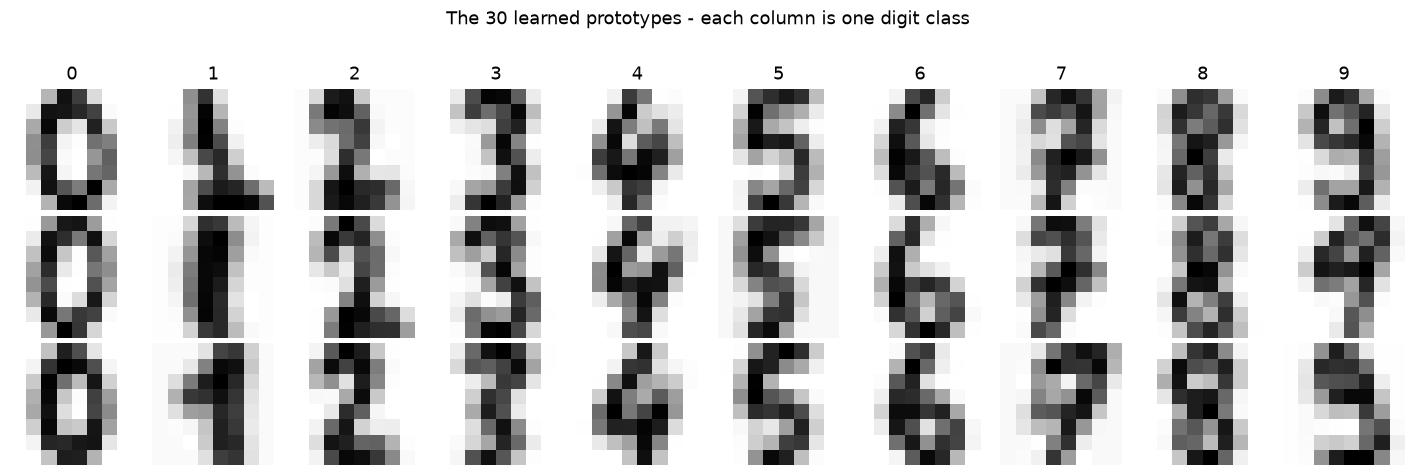


Most common confusions (2 or more):
   3 x digit 2 predicted as 8
   3 x digit 8 predicted as 1
   3 x digit 9 predicted as 7
   2 x digit 4 predicted as 8
   2 x digit 9 predicted as 8


In [36]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 9 (c)
yd_pred = predict(Xd_te, protos_d, labels_d)
acc_d = (yd_pred == yd_te).mean()
knn_d = KNeighborsClassifier(n_neighbors=1).fit(Xd_tr, yd_tr).score(Xd_te, yd_te)

print(f"LVQ test accuracy : {acc_d:.2%}  ({len(protos_d)} stored vectors)")
print(f"1-NN test accuracy: {knn_d:.2%}  ({len(Xd_tr)} stored vectors)")
print(f"LVQ stores {len(Xd_tr) / len(protos_d):.0f}x less for {knn_d - acc_d:.2%} less accuracy")

fig, axes = plt.subplots(3, 10, figsize=(13, 4.2))
for k in range(len(protos_d)):
    c = labels_d[k]
    row = list(np.flatnonzero(labels_d == c)).index(k)
    ax = axes[row, c]
    ax.imshow(protos_d[k].reshape(8, 8), cmap="gray_r")
    ax.axis("off")
    if row == 0:
        ax.set_title(str(c))
plt.suptitle("The 30 learned prototypes - each column is one digit class", y=1.02)
plt.tight_layout()
plt.show()

cm_d = confusion_matrix(yd_te, yd_pred)
worst = [(i, j, cm_d[i, j]) for i in range(10) for j in range(10) if i != j and cm_d[i, j] >= 2]
print("\nMost common confusions (2 or more):")
for i, j, k in sorted(worst, key=lambda t: -t[2])[:6]:
    print(f"   {k} x digit {i} predicted as {j}")

### Task 9 (d)

> Write the summary report: preprocessing, model architecture and the rationale for the hyperparameters, the training process and the evaluation metrics.

In [37]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 9 (d)
print("=" * 72)
print("SUMMARY REPORT - LVQ on UCI Optical Recognition of Handwritten Digits")
print("=" * 72)
print()
print("1. DATA PREPROCESSING")
print(f"   Source      : UCI ML Repository, dataset 80, via sklearn.datasets.load_digits")
print(f"   Size        : {Xd_raw.shape[0]} samples, {Xd_raw.shape[1]} features (8x8 greyscale), "
      f"{len(np.unique(yd))} classes")
print(f"   Split       : 70/30 stratified, random_state={SEED} "
      f"-> {len(Xd_tr)} train / {len(Xd_te)} test")
print( "   Scaling     : divided by 16 to put every pixel in [0, 1]. All features share")
print( "                 one unit already, so StandardScaler is the wrong tool here - it")
print( "                 would amplify border pixels that are 0 in almost every sample.")
print(f"   Missing     : none ({np.isnan(Xd_raw).sum()} NaNs)")
print()
print("2. MODEL ARCHITECTURE")
print(f"   Type        : LVQ1, written from scratch (no sklearn estimator)")
print(f"   Input layer : {protos_d.shape[1]} nodes, one per pixel")
print(f"   Output layer: {protos_d.shape[0]} prototypes, 3 per class, each a vector in the")
print( "                 same 64-D space as the inputs")
print( "   Decision    : nearest prototype by Euclidean distance; the sample takes that")
print( "                 prototype's class label")
print()
print("3. HYPERPARAMETERS AND WHY")
print( "   prototypes/class = 3 : a handwritten digit has several distinct styles (a 7")
print( "                          with and without a bar, an open and a closed 4). One")
print( "                          prototype has to average them into a blur; Task 8 (c)")
print( "                          showed accuracy rising with k and then flattening.")
print(f"   alpha0 = 0.2         : Task 8 (a) swept 0.01 to 0.8. Below 0.05 the prototypes")
print( "                          barely leave their starting points inside 30 epochs;")
print( "                          above 0.5 late updates undo earlier learning.")
print(f"   epochs = 30          : Task 8 (b) showed the curve flat well before this.")
print( "   decay: alpha_t = alpha0 * (1 - t/T), linear to zero, so the last epochs only")
print( "          make fine corrections.")
print( "   Samples are reshuffled every epoch so presentation order cannot bias the result.")
print()
print("4. TRAINING PROCESS")
print(f"   {len(Xd_tr)} samples x 30 epochs = {len(Xd_tr) * 30:,} single-winner updates.")
print( "   Each step: find the nearest prototype, then move it towards the sample if the")
print( "   labels agree and away if they do not. Only the winner is touched.")
print(f"   Train accuracy went {hist_d[0, 2]:.2%} (epoch 1) -> {hist_d[-1, 2]:.2%} (epoch 30).")
print()
print("5. EVALUATION")
print(f"   Test accuracy        : {acc_d:.2%}")
print(f"   Train accuracy       : {hist_d[-1, 2]:.2%}  "
      f"(gap {hist_d[-1, 2] - acc_d:+.2%}, so little overfitting)")
print(f"   Macro F1             : "
      f"{__import__('sklearn.metrics', fromlist=['f1_score']).f1_score(yd_te, yd_pred, average='macro'):.3f}")
print(f"   1-NN baseline        : {knn_d:.2%} using {len(Xd_tr)} stored vectors")
print(f"   Compression          : {len(Xd_tr) / len(protos_d):.0f}x fewer vectors than 1-NN, "
      f"for {knn_d - acc_d:.2%} less accuracy")
print()
print("6. CONCLUSION")
print( "   LVQ reaches within a few points of 1-NN while storing 30 vectors instead of")
print(f"   {len(Xd_tr)}. The prototype images in Task 9 (c) show why it works: each one")
print( "   settles into a readable average digit, so the model is inspectable in a way")
print( "   that a weight matrix is not. The errors that remain are the pairs that look")
print( "   alike at 8x8 resolution, which is a limit of the data rather than the method.")
print("=" * 72)

SUMMARY REPORT - LVQ on UCI Optical Recognition of Handwritten Digits

1. DATA PREPROCESSING
   Source      : UCI ML Repository, dataset 80, via sklearn.datasets.load_digits
   Size        : 1797 samples, 64 features (8x8 greyscale), 10 classes
   Split       : 70/30 stratified, random_state=58 -> 1257 train / 540 test
   Scaling     : divided by 16 to put every pixel in [0, 1]. All features share
                 one unit already, so StandardScaler is the wrong tool here - it
                 would amplify border pixels that are 0 in almost every sample.
   Missing     : none (0 NaNs)

2. MODEL ARCHITECTURE
   Type        : LVQ1, written from scratch (no sklearn estimator)
   Input layer : 64 nodes, one per pixel
   Output layer: 30 prototypes, 3 per class, each a vector in the
                 same 64-D space as the inputs
   Decision    : nearest prototype by Euclidean distance; the sample takes that
                 prototype's class label

3. HYPERPARAMETERS AND WHY
   prototypes/

---

## End of Lab 05

All 9 tasks (36 parts) completed by **Zain Ul Wahaj** - **FA23-BAI-058**.